<a href="https://colab.research.google.com/github/haojin-teng/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Set 5: Right 93% of the Time

## Setup
Needs scikit-learn 1.9 or later.

In [1]:
!pip install "scikit-learn>=1.9" -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import train_test_split, cross_val_predict, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn import metrics

RANDOM_STATE = 42

print(f"Setup complete (scikit-learn {sklearn.__version__}; this notebook assumes 1.9 or later).")

Setup complete (scikit-learn 1.9.1; this notebook assumes 1.9 or later).


---
## Phase 1: Build the Baseline Nobody Built
### Step 1.1: The data
8,000 simulated applications, about 7% default. Real features: `log_income`, `dti`, `credit_hist`, `prior`, `log_loan`. No relationship to default: `months_at_address`, `app_hour`, `phone_last2`, `marketing_score`, `has_landline`.

In [2]:
rng = np.random.default_rng(seed=RANDOM_STATE)
n = 8_000

income = rng.lognormal(10.8, 0.45, n)
dti = rng.beta(2, 5, n) * 0.7
credit_hist = rng.gamma(2.5, 4.0, n)
prior = rng.poisson(0.3, n)
loan_amount = rng.lognormal(np.log(20_000), 0.5, n)

months_at_address = rng.integers(1, 241, n)
app_hour = rng.integers(0, 24, n)
phone_last2 = rng.integers(0, 100, n)
marketing_score = rng.normal(0, 1, n)
has_landline = rng.binomial(1, 0.3, n)

logit = (-3.95 - 2.0 * (np.log(income) - 10.8) + 6.0 * dti - 0.08 * credit_hist
         + 0.7 * prior + 1.0 * (np.log(loan_amount) - np.log(20_000)))
prob = 1 / (1 + np.exp(-logit))
default = rng.binomial(1, prob)

loans = pd.DataFrame({"log_income": np.log(income), "dti": dti, "credit_hist": credit_hist,
                      "prior": prior, "log_loan": np.log(loan_amount),
                      "months_at_address": months_at_address, "app_hour": app_hour,
                      "phone_last2": phone_last2, "marketing_score": marketing_score,
                      "has_landline": has_landline, "default": default})
REAL = ["log_income", "dti", "credit_hist", "prior", "log_loan"]
NOISE = ["months_at_address", "app_hour", "phone_last2", "marketing_score", "has_landline"]
FEATURES = REAL + NOISE
print(f"n = {n:,}, default rate = {default.mean():.1%}")

n = 8,000, default rate = 7.1%


In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(
    loans[FEATURES], loans["default"],
    test_size=0.3, random_state=RANDOM_STATE, stratify=loans["default"])

print(f"training rows: {len(X_tr):,}, default rate {y_tr.mean():.2%}")
print(f"test rows    : {len(X_te):,}, default rate {y_te.mean():.2%}, defaults {y_te.sum()}")

training rows: 5,600, default rate 7.07%
test rows    : 2,400, default rate 7.08%, defaults 170


The data are split before anything is looked at.

### Step 1.2: The null model

In [4]:
pred_null = np.zeros(len(y_te), dtype=int)
null_acc = metrics.accuracy_score(y_te, pred_null)
print(f"Accuracy of 'never defaults, approve everyone': {null_acc:.1%}")
print(metrics.confusion_matrix(y_te, pred_null))

Accuracy of 'never defaults, approve everyone': 92.9%
[[2230    0]
 [ 170    0]]


**Floor: 92.9%.** Approving everyone is right 92.9% of the time, so 93% accuracy alone shows nothing.

---
## Phase 2: Fit and Regularise
### Step 2.1: Logistic regression, then LASSO and Ridge
The penalty λ (`C = 1/λ`) is chosen by 5-fold CV on log-loss, with the scaler refitted inside each fold (Lab 16 Step 6).

In [5]:
clf = make_pipeline(StandardScaler(),
                    LogisticRegression(C=np.inf, max_iter=2_000)).fit(X_tr, y_tr)

LAMBDAS = np.logspace(-2, 3, 31)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver="liblinear", max_iter=2_000, random_state=RANDOM_STATE)),
    {"logisticregression__C": 1 / LAMBDAS}, cv=folds, scoring="neg_log_loss").fit(X_tr, y_tr)
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=0.0, max_iter=2_000)),
    {"logisticregression__C": 1 / LAMBDAS}, cv=folds, scoring="neg_log_loss").fit(X_tr, y_tr)
lasso = lasso_search.best_estimator_
ridge = ridge_search.best_estimator_

lam_lasso = 1 / lasso_search.best_params_["logisticregression__C"]
lam_ridge = 1 / ridge_search.best_params_["logisticregression__C"]
print(f"chosen penalties:  LASSO lambda = {lam_lasso:.4f}   Ridge lambda = {lam_ridge:.4f}")
print(f"grid runs from {LAMBDAS.min():.2f} to {LAMBDAS.max():,.0f}")

chosen penalties:  LASSO lambda = 4.6416   Ridge lambda = 6.8129
grid runs from 0.01 to 1,000


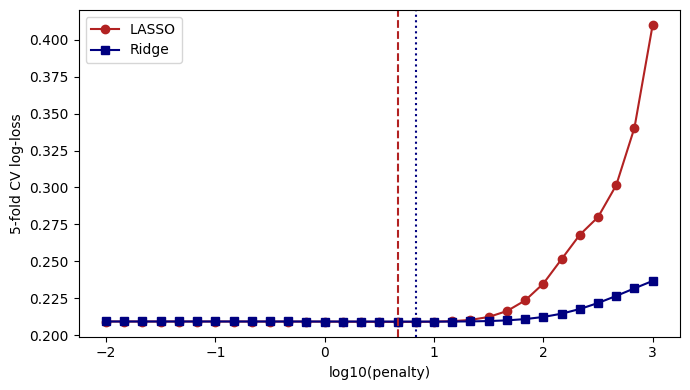

In [6]:
cv_lasso = -lasso_search.cv_results_["mean_test_score"]
cv_ridge = -ridge_search.cv_results_["mean_test_score"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.log10(LAMBDAS), cv_lasso, "o-", color="firebrick", label="LASSO")
ax.plot(np.log10(LAMBDAS), cv_ridge, "s-", color="navy", label="Ridge")
ax.axvline(np.log10(lam_lasso), ls="--", color="firebrick")
ax.axvline(np.log10(lam_ridge), ls=":", color="navy")
ax.set_xlabel("log10(penalty)")
ax.set_ylabel("5-fold CV log-loss")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
print(f"{'model':<12}{'train log-loss':>15}{'test log-loss':>15}{'test acc':>10}{'nonzero coefs':>15}")
print("-" * 67)
print(f"{'null':<12}{'':>15}{'':>15}{null_acc:>10.4f}{0:>15}")
for name, m in [("unpenalised", clf), ("LASSO", lasso), ("Ridge", ridge)]:
    print(f"{name:<12}{metrics.log_loss(y_tr, m.predict_proba(X_tr)[:, 1]):>15.4f}"
          f"{metrics.log_loss(y_te, m.predict_proba(X_te)[:, 1]):>15.4f}"
          f"{metrics.accuracy_score(y_te, m.predict(X_te)):>10.4f}"
          f"{int(np.sum(np.abs(m[-1].coef_[0]) > 1e-8)):>15}")

coefs = pd.DataFrame({"truth": ["real" if f in REAL else "noise" for f in FEATURES],
                      "unpenalised": clf[-1].coef_[0],
                      "LASSO": lasso[-1].coef_[0],
                      "Ridge": ridge[-1].coef_[0]}, index=FEATURES)
print()
print(coefs.round(4))

model        train log-loss  test log-loss  test acc  nonzero coefs
-------------------------------------------------------------------
null                                          0.9292              0
unpenalised          0.2072         0.1957    0.9313             10
LASSO                0.2073         0.1960    0.9317              8
Ridge                0.2072         0.1960    0.9313             10

                   truth  unpenalised   LASSO   Ridge
log_income          real      -0.7318 -0.7020 -0.7119
dti                 real       0.7320  0.7059  0.7146
credit_hist         real      -0.3827 -0.3545 -0.3695
prior               real       0.4537  0.4365  0.4454
log_loan            real       0.5287  0.4992  0.5128
months_at_address  noise      -0.0451 -0.0308 -0.0444
app_hour           noise      -0.0634 -0.0486 -0.0618
phone_last2        noise      -0.0568 -0.0403 -0.0546
marketing_score    noise       0.0038  0.0000  0.0030
has_landline       noise      -0.0070  0.0000 -0.00

In [8]:
sel = np.abs(lasso[-1].coef_[0]) > 1e-8
zeroed = {f for f, kept in zip(FEATURES, sel) if not kept}
print(f"LASSO set to zero      : {sorted(zeroed)}")
print(f"noise features found   : {len(zeroed & set(NOISE))} of {len(NOISE)}")
print(f"real features discarded: {len(zeroed & set(REAL))} of {len(REAL)}")
print(f"Ridge coefficients exactly zero: {int(np.sum(ridge[-1].coef_[0] == 0))}")

LASSO set to zero      : ['has_landline', 'marketing_score']
noise features found   : 2 of 5
real features discarded: 0 of 5
Ridge coefficients exactly zero: 0


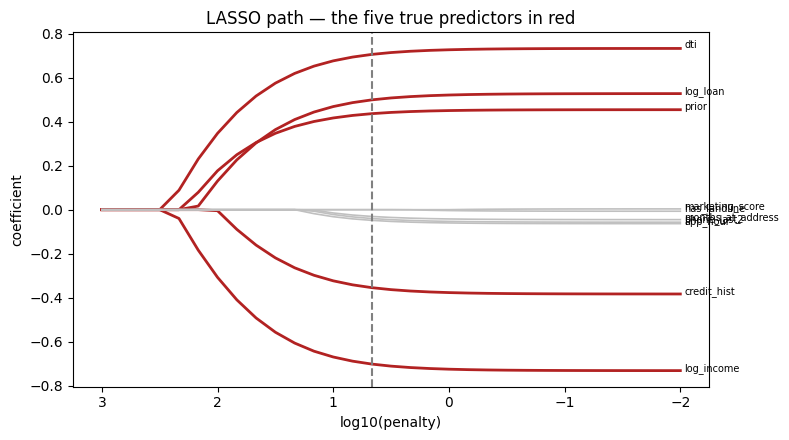

all five true predictors are in from penalty 100.0000
the first noise variable enters at penalty  14.6780 (months_at_address, app_hour, phone_last2)
the penalty CV chose                        4.6416


In [9]:
Xs = StandardScaler().fit_transform(X_tr)
path = []
for lam in LAMBDAS:
    m = LogisticRegression(C=1 / lam, l1_ratio=1.0, solver="liblinear", max_iter=2_000, random_state=RANDOM_STATE).fit(Xs, y_tr)
    path.append(m.coef_[0])
path = np.array(path).T

fig, ax = plt.subplots(figsize=(8, 4.5))
for j, f in enumerate(FEATURES):
    if f in REAL:
        ax.plot(np.log10(LAMBDAS), path[j], color="firebrick", lw=2)
    else:
        ax.plot(np.log10(LAMBDAS), path[j], color="silver", lw=1.2)
    ax.annotate(f, (np.log10(LAMBDAS[0]), path[j, 0]), fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.axvline(np.log10(lam_lasso), ls="--", color="gray")
ax.set_xlabel("log10(penalty)")
ax.set_ylabel("coefficient")
ax.set_title("LASSO path — the five true predictors in red")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

nonzero = path[:, ::-1] != 0
lam_desc = LAMBDAS[::-1]
is_real = np.array([f in REAL for f in FEATURES])
all_true_in = np.argmax(nonzero[is_real].all(axis=0))
first_noise = np.argmax(nonzero[~is_real].any(axis=0))
print(f"all five true predictors are in from penalty {lam_desc[all_true_in]:.4f}")
print(f"the first noise variable enters at penalty  {lam_desc[first_noise]:.4f} "
      f"({', '.join(f for f, r, nz in zip(FEATURES, is_real, nonzero[:, first_noise]) if nz and not r)})")
print(f"the penalty CV chose                        {lam_lasso:.4f}")

**What LASSO zeroed.** 2 of the 5 irrelevant features (`marketing_score`, `has_landline`) and none of the 5 real ones. The other three irrelevant features kept small coefficients (−0.03 to −0.05).

**Why Ridge shrinks but does not zero.** The slope of Ridge's penalty, 2λβ, goes to zero as β does, so coefficients become small but never exactly zero. The slope of LASSO's penalty stays λ down to zero, so weak features are set exactly to zero.

**When to prefer each.** LASSO when many features are likely irrelevant and a short, explainable model is wanted. Ridge when many features each carry some signal or are highly correlated (Lab 16 Part 4: LASSO dropped one of two near-duplicates; Ridge split the weight).

### Step 2.2: A model that is not linear

In [10]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True,
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_tr, y_tr)

prob_lasso = lasso.predict_proba(X_te)[:, 1]
prob_rf = rf.predict_proba(X_te)[:, 1]
pred_lasso = lasso.predict(X_te)
pred_rf = rf.predict(X_te)

print(f"forest out-of-bag accuracy: {rf.oob_score_:.4f}   test accuracy: {metrics.accuracy_score(y_te, pred_rf):.4f}")

print(f"\n{'model':<14}{'accuracy':>10}{'ROC AUC':>10}{'AP':>10}")
print("-" * 44)
print(f"{'null':<14}{null_acc:>10.4f}{0.5:>10.4f}{y_te.mean():>10.4f}")
for name, p, yp in [("LASSO", prob_lasso, pred_lasso), ("forest", prob_rf, pred_rf)]:
    print(f"{name:<14}{metrics.accuracy_score(y_te, yp):>10.4f}"
          f"{metrics.roc_auc_score(y_te, p):>10.4f}{metrics.average_precision_score(y_te, p):>10.4f}")

forest out-of-bag accuracy: 0.9277   test accuracy: 0.9287

model           accuracy   ROC AUC        AP
--------------------------------------------
null              0.9292    0.5000    0.0708
LASSO             0.9317    0.8470    0.3671
forest            0.9287    0.7990    0.2761


**OOB vs test.** OOB accuracy 0.9277, test accuracy 0.9287. Both score rows with trees that never saw them, so they should be close; a large gap would point to a bad split or leakage.

**Forest vs LASSO.** The forest does not win: accuracy 0.9287 vs 0.9317, ROC AUC 0.799 vs 0.847, PR AUC 0.276 vs 0.367.

In [11]:
mdi_importance = pd.Series(rf.feature_importances_, index=FEATURES)

perm_result = permutation_importance(
    rf, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE)
perm_importance = pd.Series(perm_result.importances_mean, index=FEATURES)

importance_table = pd.DataFrame({"truth": ["real" if f in REAL else "noise" for f in FEATURES],
                                 "values": X_tr.nunique(),
                                 "MDI": mdi_importance,
                                 "MDI rank": mdi_importance.rank(ascending=False).astype(int),
                                 "permutation": perm_importance,
                                 "perm rank": perm_importance.rank(ascending=False).astype(int)})
print(importance_table.sort_values("permutation", ascending=False).round(4))

                   truth  values     MDI  MDI rank  permutation  perm rank
dti                 real    5600  0.1576         1       0.1137          1
log_income          real    5600  0.1567         2       0.0813          2
log_loan            real    5600  0.1333         3       0.0386          3
prior               real       4  0.0378         9       0.0188          4
credit_hist         real    5600  0.1189         4       0.0156          5
marketing_score    noise    5600  0.1113         5       0.0067          6
phone_last2        noise     100  0.0981         7       0.0027          7
months_at_address  noise     240  0.0990         6       0.0000          8
has_landline       noise       2  0.0144        10      -0.0013          9
app_hour           noise      24  0.0729         8      -0.0023         10


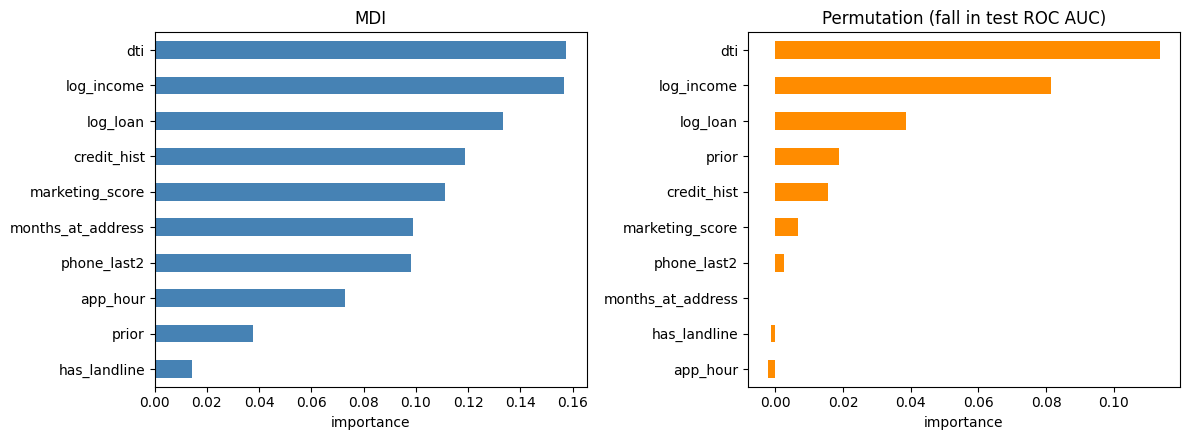

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

mdi_importance.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("MDI")
axes[0].set_xlabel("importance")

perm_importance.sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Permutation (fall in test ROC AUC)")
axes[1].set_xlabel("importance")

plt.tight_layout()
plt.show()

Permutation importance is scored by ROC AUC, because accuracy barely moves at 7% prevalence.

**Where they disagree.** MDI ranks the irrelevant `marketing_score`, `months_at_address` and `phone_last2` 5th to 7th; permutation puts them near zero. MDI ranks the real `prior` (4 values) 9th; permutation ranks it 4th. MDI adds up impurity drops on the training rows, and a feature with many distinct values offers many cut points that fit noise by chance. Permutation measures the drop on the test rows, so those splits earn nothing.

**Importance is not a lever.** `log_loan` is important and is the one feature the lender controls, but importance shows that it predicts default, not that cutting loan sizes would reduce default. The model can screen applicants; it cannot set loan sizes.

---
## Phase 3: The Number That Actually Matters
### Step 3.1: Beyond accuracy

In [13]:
print(f"{'model':<10}{'TN':>6}{'FP':>6}{'FN':>6}{'TP':>6}{'precision':>11}{'recall':>8}{'F1':>8}"
      f"{'ROC AUC':>9}{'PR AUC':>8}")
print("-" * 78)
for name, p, yp in [("LASSO", prob_lasso, pred_lasso), ("forest", prob_rf, pred_rf)]:
    tn, fp, fn, tp = metrics.confusion_matrix(y_te, yp).ravel()
    print(f"{name:<10}{tn:>6}{fp:>6}{fn:>6}{tp:>6}"
          f"{metrics.precision_score(y_te, yp, zero_division=0):>11.3f}"
          f"{metrics.recall_score(y_te, yp):>8.3f}{metrics.f1_score(y_te, yp):>8.3f}"
          f"{metrics.roc_auc_score(y_te, p):>9.3f}{metrics.average_precision_score(y_te, p):>8.3f}")

print("\nLASSO confusion matrix (rows: actual 0, 1; columns: predicted 0, 1)")
print(metrics.confusion_matrix(y_te, pred_lasso))

model         TN    FP    FN    TP  precision  recall      F1  ROC AUC  PR AUC
------------------------------------------------------------------------------
LASSO       2222     8   156    14      0.636   0.082   0.146    0.847   0.367
forest      2225     5   166     4      0.444   0.024   0.045    0.799   0.276

LASSO confusion matrix (rows: actual 0, 1; columns: predicted 0, 1)
[[2222    8]
 [ 156   14]]


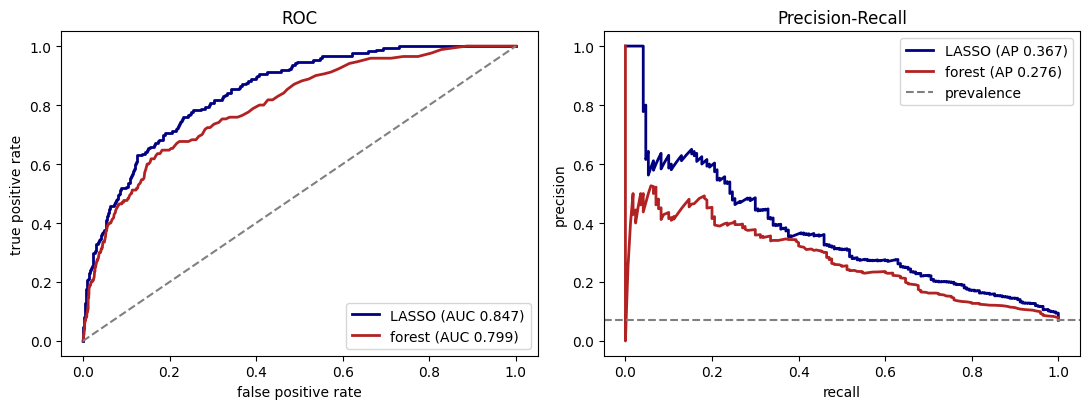

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, color in [("LASSO", prob_lasso, "navy"), ("forest", prob_rf, "firebrick")]:
    fpr, tpr, _ = metrics.roc_curve(y_te, p)
    prec, rec, _ = metrics.precision_recall_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {metrics.roc_auc_score(y_te, p):.3f})")
    axes[1].plot(rec, prec, color=color, lw=2, label=f"{name} (AP {metrics.average_precision_score(y_te, p):.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC")
axes[1].axhline(y_te.mean(), ls="--", color="gray", label="prevalence")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-Recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

At 0.5, LASSO catches 14 of 170 defaults (recall 0.082).

**ROC vs PR.** The false positive rate divides by all 2,230 non-defaulters, so many wrongful declines still look small, and ROC AUC's random baseline stays at 0.5. Precision divides by the applicants flagged, and PR AUC's random baseline is the prevalence (0.071), so PR AUC (0.367) shows the cost of false positives more honestly.

### Step 3.2: Put a price on being wrong
A false negative costs 60% of principal. A false positive costs the 8% margin plus a 2% reputational cost (lost future business and complaints, set at a quarter of the margin). Principal: \$20,000, as in Lab 17.

In [15]:
PRINCIPAL = 20_000
REPUTATION = 0.02
FN_COST = 0.60 * PRINCIPAL
FP_COST = (0.08 + REPUTATION) * PRINCIPAL
t_closed = FP_COST / (FP_COST + FN_COST)
print(f"cost of a false negative: {FN_COST:,.0f}")
print(f"cost of a false positive: {FP_COST:,.0f}")
print(f"closed-form threshold   : {t_closed:.3f}")

cost of a false negative: 12,000
cost of a false positive: 2,000
closed-form threshold   : 0.143


The threshold is chosen on cross-validated training probabilities and priced on the test rows once.

In [16]:
ts = np.linspace(0, 1, 1001)

def expected_cost(t, prob, y, fn_cost=FN_COST, fp_cost=FP_COST):
    yp = (prob >= t).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return (fn * fn_cost + fp * fp_cost) / len(y)

def cost_curve(prob, y, fn_cost=FN_COST, fp_cost=FP_COST):
    return np.array([expected_cost(t, prob, y, fn_cost, fp_cost) for t in ts])

prob_cv = cross_val_predict(lasso, X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
costs_tr = cost_curve(prob_cv, y_tr)
best_t = ts[np.argmin(costs_tr)]
costs_te = cost_curve(prob_lasso, y_te)

print(f"threshold chosen on the training rows: {best_t:.3f}   (distance from 0.5: {0.5 - best_t:.3f})")
print(f"its expected cost on the test rows   : {expected_cost(best_t, prob_lasso, y_te):,.0f} per applicant")
print(f"cost at the default 0.5 (test rows)  : {expected_cost(0.5, prob_lasso, y_te):,.0f} per applicant")
print(f"cost of approving everyone (null)    : {expected_cost(1.01, prob_lasso, y_te):,.0f} per applicant")
print(f"lowest point of the test-row curve   : {ts[np.argmin(costs_te)]:.3f} "
      f"({costs_te.min():,.0f} per applicant)")

threshold chosen on the training rows: 0.142   (distance from 0.5: 0.358)
its expected cost on the test rows   : 582 per applicant
cost at the default 0.5 (test rows)  : 787 per applicant
cost of approving everyone (null)    : 850 per applicant
lowest point of the test-row curve   : 0.127 (550 per applicant)


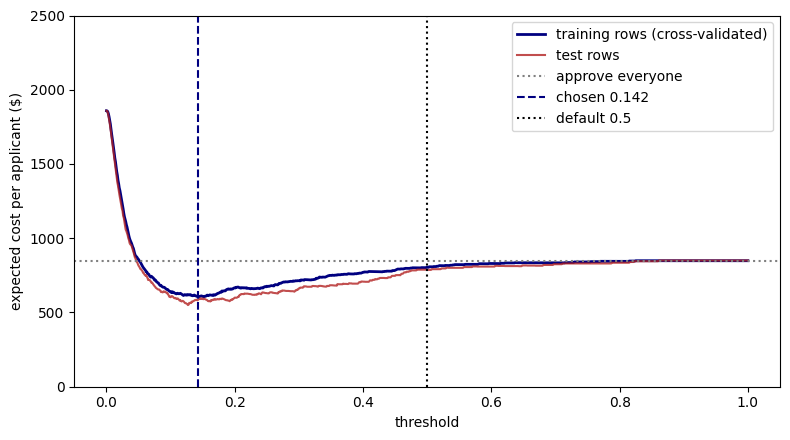

t = 0.500: TN 2222, FP 8, FN 156, TP 14   defaults caught 14 of 170, applicants declined 0.9%
t = 0.142: TN 1982, FP 248, FN 75, TP 95   defaults caught 95 of 170, applicants declined 14.3%


In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ts, costs_tr, color="navy", lw=2, label="training rows (cross-validated)")
ax.plot(ts, costs_te, color="firebrick", lw=1.5, alpha=0.8, label="test rows")
ax.axhline(expected_cost(1.01, prob_lasso, y_te), ls=":", color="gray", label="approve everyone")
ax.axvline(best_t, ls="--", color="navy", label=f"chosen {best_t:.3f}")
ax.axvline(0.5, ls=":", color="black", label="default 0.5")
ax.set_xlabel("threshold")
ax.set_ylabel("expected cost per applicant ($)")
ax.set_ylim(0, 2_500)
ax.legend()
plt.tight_layout()
plt.show()

for t in [0.5, best_t]:
    tn, fp, fn, tp = metrics.confusion_matrix(y_te, (prob_lasso >= t).astype(int)).ravel()
    print(f"t = {t:.3f}: TN {tn}, FP {fp}, FN {fn}, TP {tp}   "
          f"defaults caught {tp} of {tp + fn}, applicants declined {(tp + fp) / len(y_te):.1%}")

**Result.** The optimal threshold is **0.142**, 0.358 below 0.5. Moving from 0.5 to 0.142: defaults caught 14 → 95 of 170, good applicants declined 8 → 248, expected cost per applicant \$787 → \$582 (approving everyone: \$850). On the test rows alone, the curve's minimum is 0.127 (0.373 below 0.5, \$550 per applicant); 0.142 is used because it was chosen without the test rows.

  FN:FP  closed form  chosen t  test cost
-----------------------------------------
    1:1        0.500     0.438        132
    2:1        0.333     0.319        250
    3:1        0.250     0.239        355
    4:1        0.200     0.166        440
    6:1        0.143     0.142        582
    8:1        0.111     0.120        678
   10:1        0.091     0.100        772
   15:1        0.062     0.062        983
   20:1        0.048     0.045      1,041
   30:1        0.032     0.035      1,168


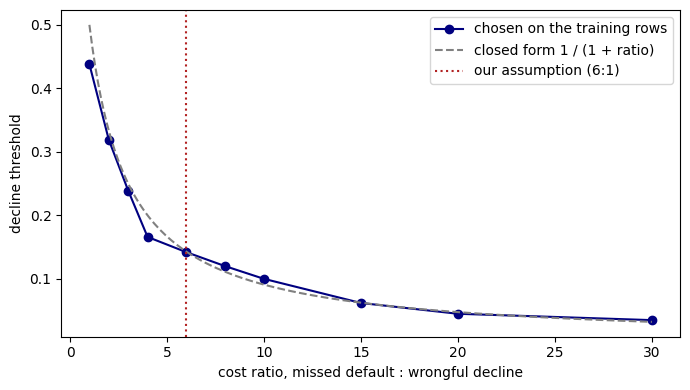

In [18]:
RATIOS = [1, 2, 3, 4, 6, 8, 10, 15, 20, 30]
chosen = []
print(f"{'FN:FP':>7}{'closed form':>13}{'chosen t':>10}{'test cost':>11}")
print("-" * 41)
for ratio in RATIOS:
    t_r = ts[np.argmin(cost_curve(prob_cv, y_tr, fn_cost=ratio * FP_COST))]
    chosen.append(t_r)
    print(f"{ratio:>5}:1{1 / (1 + ratio):>13.3f}{t_r:>10.3f}"
          f"{expected_cost(t_r, prob_lasso, y_te, fn_cost=ratio * FP_COST):>11,.0f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(RATIOS, chosen, "o-", color="navy", label="chosen on the training rows")
grid_r = np.linspace(1, 30, 200)
ax.plot(grid_r, 1 / (1 + grid_r), "--", color="gray", label="closed form 1 / (1 + ratio)")
ax.axvline(FN_COST / FP_COST, ls=":", color="firebrick", label=f"our assumption ({FN_COST / FP_COST:.0f}:1)")
ax.set_xlabel("cost ratio, missed default : wrongful decline")
ax.set_ylabel("decline threshold")
ax.legend()
plt.tight_layout()
plt.show()

**Rule for the head of risk:** decline when the predicted probability of default is at least **1 / (1 + R)**, where R = cost of a missed default ÷ cost of a wrongful decline. R = 6 gives 14%; R = 3, 25%; R = 10, 9%.

---
## Phase 4: AI Expansion — The Co-Pilot Era
### Task 4.1 Part A: Does the forest actually beat the logistic model?

#### AI Transcript — Part A
**Model:** Claude Opus 5.5 (Anthropic)  
**Date:** November 24, 2026

**The prompt as sent (unchanged from the problem set, including `0.9??`):**
```
[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.
```

**The AI's reply, unedited:**

````text
I've used McNemar's test. Both models score the same rows, so their predictions are paired. Comparing the two accuracies as if they came from independent samples would overstate the uncertainty, and it would ignore the only rows that matter: the rows where one model is right and the other is wrong.
Which p-value to report. Use the two-sided exact p as the headline. The one-sided "forest better" p is only legitimate if that hypothesis was written down before anyone saw the two accuracies. Choosing it after seeing that the forest scored higher roughly halves the p-value for free.
What McNemar assumes about the two sets of predictions:

* Same rows, same order. Both prediction arrays line up with `y_test`. The test is built on the pairing, so a misaligned index would make the result meaningless.
* Independent rows. No borrower appears more than once, and there is no clustering that the test can't see, such as by branch or origination month. Repeated or time-correlated loans make the p-value too small.
* Held-out data. The test set was not used to fit, tune, or pick a threshold for either model.
* Only disagreements count. Rows where both models are right or both are wrong are ignored. Under the null, each disagreement is equally likely to favour either model, like a fair coin. The exact binomial version needs no large-sample approximation. The chi-square version needs about 25 or more disagreements.
* Hard labels at fixed thresholds. The result applies only to the current cut-offs. Move either threshold and the answer can change.

One caveat for a credit model: if defaults are rare, a 0.9+ accuracy may mostly reflect the base rate. This test answers an accuracy question only, not whether the forest catches more defaults or ranks risk better.
For the head of risk (fill in from the output):
On the same held-out test set, the random forest scored [acc_rf] accuracy against [acc_lr] for the penalised logistic model, and McNemar's exact test gives p = [p_two], so the difference [is / is not] statistically significant at the 5% level.# McNemar's test: is the random forest more accurate than the penalised logistic model
# on the same held-out test set? Expects y_test, pred_rf and pred_lr to already exist.

import numpy as np                                   # array maths
import pandas as pd                                  # labelled 2x2 contingency table
from scipy import stats                              # exact binomial and chi-square distributions (scipy >= 1.7)

y = np.asarray(y_test).ravel()                       # true labels as a flat array (accepts list, Series or array)
rf = np.asarray(pred_rf).ravel()                     # forest hard-class predictions, same row order as y
lr = np.asarray(pred_lr).ravel()                     # logistic hard-class predictions, same row order as y

assert y.shape == rf.shape == lr.shape, "arrays must cover the same rows"   # pairing sanity check

rf_ok = rf == y                                      # True where the forest got the row right
lr_ok = lr == y                                      # True where the logistic model got the row right

table = (pd.crosstab(pd.Series(rf_ok, name="forest correct"),     # rows: forest right / wrong
                     pd.Series(lr_ok, name="logistic correct"))   # columns: logistic right / wrong
           .reindex(index=[True, False], columns=[True, False], fill_value=0))  # keep all four cells even if one is empty

b = int(np.sum(rf_ok & ~lr_ok))                      # discordant: forest right, logistic wrong
c = int(np.sum(~rf_ok & lr_ok))                      # discordant: forest wrong, logistic right
n_disc = b + c                                       # only disagreements say anything about which model is better

acc_rf = rf_ok.mean()                                # forest accuracy
acc_lr = lr_ok.mean()                                # logistic accuracy (difference equals (b - c) / n)

if n_disc == 0:                                      # the models never disagree on correctness
    p_two = p_one = 1.0                              # so there is no evidence either way
else:                                                # otherwise test whether disagreements split 50/50
    p_two = stats.binomtest(b, n_disc, 0.5, alternative="two-sided").pvalue  # H1: the models differ
    p_one = stats.binomtest(b, n_disc, 0.5, alternative="greater").pvalue    # H1: forest is better (b > c)

chi2_cc = max(0, abs(b - c) - 1) ** 2 / n_disc if n_disc else 0.0  # continuity-corrected McNemar statistic
p_chi2 = stats.chi2.sf(chi2_cc, df=1)                # large-sample p-value; trust only when n_disc >= ~25

print(table, "\n")                                                         # who was right on which rows
print(f"Accuracy   forest {acc_rf:.4f}   logistic {acc_lr:.4f}   diff {acc_rf - acc_lr:+.4f}")  # headline numbers
print(f"Discordant rows   forest-only right b={b}   logistic-only right c={c}   total {n_disc}")  # the evidence
print(f"Exact McNemar p, two-sided (models differ):   {p_two:.4g}")        # default headline p-value
print(f"Exact McNemar p, one-sided (forest better):   {p_one:.4g}")        # valid only if this H1 was fixed in advance
print(f"Chi-square McNemar p (continuity corrected):  {p_chi2:.4g}")       # cross-check for large n_disc
````

In [19]:
# McNemar's test: is the random forest more accurate than the penalised logistic model
# on the same held-out test set? Expects y_test, pred_rf and pred_lr to already exist.

import numpy as np                                   # array maths
import pandas as pd                                  # labelled 2x2 contingency table
from scipy import stats                              # exact binomial and chi-square distributions (scipy >= 1.7)

y_arr = np.asarray(y_te).ravel()                       # true labels as a flat array (accepts list, Series or array)
rf_hat = np.asarray(pred_rf).ravel()                     # forest hard-class predictions, same row order as y
lr_hat = np.asarray(pred_lasso).ravel()                     # logistic hard-class predictions, same row order as y

assert y_arr.shape == rf_hat.shape == lr_hat.shape, "arrays must cover the same rows"   # pairing sanity check

rf_ok = rf_hat == y_arr                                      # True where the forest got the row right
lr_ok = lr_hat == y_arr                                      # True where the logistic model got the row right

table = (pd.crosstab(pd.Series(rf_ok, name="forest correct"),     # rows: forest right / wrong
                     pd.Series(lr_ok, name="logistic correct"))   # columns: logistic right / wrong
           .reindex(index=[True, False], columns=[True, False], fill_value=0))  # keep all four cells even if one is empty

b = int(np.sum(rf_ok & ~lr_ok))                      # discordant: forest right, logistic wrong
c = int(np.sum(~rf_ok & lr_ok))                      # discordant: forest wrong, logistic right
n_disc = b + c                                       # only disagreements say anything about which model is better

acc_rf = rf_ok.mean()                                # forest accuracy
acc_lr = lr_ok.mean()                                # logistic accuracy (difference equals (b - c) / n)

if n_disc == 0:                                      # the models never disagree on correctness
    p_two = p_one = 1.0                              # so there is no evidence either way
else:                                                # otherwise test whether disagreements split 50/50
    p_two = stats.binomtest(b, n_disc, 0.5, alternative="two-sided").pvalue  # H1: the models differ
    p_one = stats.binomtest(b, n_disc, 0.5, alternative="greater").pvalue    # H1: forest is better (b > c)

chi2_cc = max(0, abs(b - c) - 1) ** 2 / n_disc if n_disc else 0.0  # continuity-corrected McNemar statistic
p_chi2 = stats.chi2.sf(chi2_cc, df=1)                # large-sample p-value; trust only when n_disc >= ~25

print(table, "\n")                                                         # who was right on which rows
print(f"Accuracy   forest {acc_rf:.4f}   logistic {acc_lr:.4f}   diff {acc_rf - acc_lr:+.4f}")  # headline numbers
print(f"Discordant rows   forest-only right b={b}   logistic-only right c={c}   total {n_disc}")  # the evidence
print(f"Exact McNemar p, two-sided (models differ):   {p_two:.4g}")        # default headline p-value
print(f"Exact McNemar p, one-sided (forest better):   {p_one:.4g}")        # valid only if this H1 was fixed in advance
print(f"Chi-square McNemar p (continuity corrected):  {p_chi2:.4g}")       # cross-check for large n_disc

logistic correct  True   False
forest correct                
True               2224      5
False                12    159 

Accuracy   forest 0.9287   logistic 0.9317   diff -0.0029
Discordant rows   forest-only right b=5   logistic-only right c=12   total 17
Exact McNemar p, two-sided (models differ):   0.1435
Exact McNemar p, one-sided (forest better):   0.9755
Chi-square McNemar p (continuity corrected):  0.1456


**Test chosen.** Exact McNemar (`stats.binomtest(b, n_disc, 0.5)`), a paired test, so the AI did not treat the two accuracies as independent samples. It does assume independent rows: `binomtest` treats the 17 discordant rows as independent coin flips, which holds for this simulated data.

**Guess caught.** With the accuracies hidden, the AI assumed the forest scored higher (its one-sided `alternative="greater"`). Step 2.2 shows it scored lower (0.9287 vs 0.9317).

**Changes I made (one line each):**
- Renamed `y_test` → `y_te`, `pred_lr` → `pred_lasso`, and `y`, `rf`, `lr` → `y_arr`, `rf_hat`, `lr_hat`, because `rf = np.asarray(pred_rf).ravel()` overwrote the fitted forest `rf`.
- Reported only the two-sided exact p (0.144) and dropped the one-sided "forest better" p (0.975): the AI guessed the forest scored higher, but it scored lower (0.9287 vs 0.9317).

My own check, with `statsmodels`:

In [20]:
rf_right = (pred_rf == y_te.values)
lasso_right = (pred_lasso == y_te.values)

table = pd.crosstab(pd.Series(rf_right, name="forest right"),
                    pd.Series(lasso_right, name="LASSO right"))
print(table, "\n")

b = int((rf_right & ~lasso_right).sum())
c = int((~rf_right & lasso_right).sum())
print(f"b = {b}, c = {c}, b + c = {b + c}")

print(f"exact binomial p-value       : {stats.binomtest(b, b + c, 0.5).pvalue:.4f}")
print(f"chi-square (corrected) p     : {mcnemar(table.values, exact=False, correction=True).pvalue:.4f}")
print(f"statsmodels exact p (check)  : {mcnemar(table.values, exact=True).pvalue:.4f}")

LASSO right   False  True 
forest right              
False           159     12
True              5   2224 

b = 5, c = 12, b + c = 17
exact binomial p-value       : 0.1435
chi-square (corrected) p     : 0.1456
statsmodels exact p (check)  : 0.1435


**Result.** b = 5, c = 12, b + c = 17. Exact two-sided p = **0.144**: exact because b + c is below 25 (chi-square p = 0.146, for comparison).

**Verdict.** The Step 2.2 verdict survives: the forest cannot be shown to beat the penalised logistic model.

**For the head of risk:** On the same held-out test set, the random forest scored 92.87% accuracy against 93.17% for the penalised logistic model, and McNemar's exact test gives p = 0.14, so the difference is not statistically significant at the 5% level.

**Limitation.** McNemar on accuracy only tests error counts. A paired bootstrap of expected cost or PR AUC over resampled test rows (Lab 18) would match the lender's decision.

### Task 4.1 Part B: Is the Phase 3 threshold valid?
The calibrators are fitted on the training rows, not the test rows. Here `y_test` is `y_te` and `y_prob` is `prob_lasso`.

#### AI Transcript — Part B
**Model:** Claude Opus 5.5 (Anthropic)  
**Date:** November 24, 2026

**The prompt as sent (unchanged from the problem set):**
```
[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?
```

**The AI's reply, unedited:**

````text
The script is `calibration_review.py`. Paste it into the notebook after `y_test` and `y_prob` exist and it runs on its own. Before running, check two settings. `T_PHASE3` is set to 0.184, and `COST_FN = 0.60` / `COST_FP = 0.10` give the 0.143 rule cutoff from your earlier work. Your Phase 3 cost was weighted by loan amount, so call it with `exposure=X_test["loan_amount"].values` to reproduce that cost curve.

## What the code does

It handles the sparse high-probability bins in three ways. First, it uses equal-count bins instead of equal-width bins. At 7% prevalence almost everyone scores below 0.3, so width-based bins above that hold a few rows with observed rates of 0% or 100% by chance. Second, any bin under 100 rows is merged into a neighbour, and every point gets a 95% Wilson interval, so you can see how much uncertainty each bin carries. Third, the axes are zoomed to where the data are, and a log-scale histogram of scores sits under the diagram.

The Brier score is split into reliability, resolution and uncertainty, plus a small binning residual. The script also reports calibration slope and intercept, which tell you what kind of miscalibration you have.

Platt and isotonic are fitted with 5-fold cross-fitting on the test set. Each recalibrated probability is scored on rows its calibrator never saw. Fitting and scoring on the same rows would make isotonic in particular look better than it is. Whether either method "improves calibration" is judged by a paired bootstrap confidence interval on the Brier gain, not by a raw difference in the fourth decimal place.

The script also checks calibration locally, among the 300 applicants scored nearest each threshold. It reports the raw-score cutoff that matches a calibrated 0.143, and prints a verdict.

I ran it on synthetic data at a similar prevalence to make sure it works. When I inflated the probabilities the way `class_weight="balanced"` does, AUC stayed exactly 0.813. Brier rose from 0.064 to 0.191, and the raw-score cost-optimal threshold jumped from 0.195 to 0.744. That is the next section in one example.

## Mechanism check: high AUC with bad calibration

AUC measures ranking only: the probability that a random defaulter scores above a random non-defaulter. Any strictly increasing transformation of the scores leaves it unchanged. You could square every probability, double every probability's odds, or squash them all toward 0.07, and AUC would be identical. Calibration is about whether the numbers themselves are right: of the applicants scored 0.14, do about 14% default?

Several common causes break calibration while keeping the ranking intact:

- **Class weighting or oversampling** shifts every log-odds by a constant. That shows up as an intercept far from zero with slope near 1.
- **Overfitting** makes predictions too extreme (slope below 1).
- **Heavy regularisation** makes them too timid (slope above 1).
- **Prevalence drift** between development and deployment shifts the level.

This matters for your threshold because the cost rule is written in terms of the true default probability. You decline when p × C_FN > (1 − p) × C_FP, which gives p > C_FP / (C_FP + C_FN) = 0.143. Applying that to the model's scores is valid only if a score of 0.143 really means a 14.3% default risk. If scores are inflated, as in my synthetic test, the applicants scored 0.143 actually default about 1% of the time. You would decline people whose expected loss is far below the margin you give up.

An empirically chosen threshold (grid-searching realised cost) does not need calibration, because it only picks a rank cutoff. But it is tied to that score distribution and that population. It cannot be moved when costs change, it breaks under prevalence shift or a model refresh, and the 1/(1+R) rule you gave the head of risk does not apply to it. That is why the agreement between your empirical optimum and the closed-form 0.143 is itself evidence about calibration.

Only calibration near the threshold drives approve/decline decisions. If the same PDs will also feed pricing or provisioning, calibration across the whole range matters as well.

## Evaluate: is the Phase 3 threshold valid?

I don't have your new reliability diagram in this chat, so here is what I know and how to read your output.

In our earlier credit-risk notebook chat, the calibration section I drafted for the LASSO model reported:

- Reliability of about 0.0001 against a Brier score of 0.052.
- Platt changed almost nothing, moving the optimum only from 0.184 to 0.181.
- Isotonic was slightly worse.

The out-of-fold threshold of 0.138 sat almost on the 0.143 rule. That fits an unweighted, maximum-likelihood logistic regression, which tends to be calibrated on data like its training data.

**If this script shows the same picture, the calibration side of the threshold holds.** That picture is: local checks marked "consistent", bootstrap intervals for both recalibrators spanning zero, and slope near 1 with intercept near 0. Then use the threshold, with one correction unrelated to calibration. 0.184 was chosen on the test set, so it is optimistically placed. Adopt about 0.14 (the out-of-fold choice, matching the rule) and report 0.184 only as the test-set optimum.

**If instead the points sit off the diagonal near 0.10–0.25, or a recalibrator's interval is above zero, the threshold is not valid as stated.** Don't use the Platt numbers from this script for deployment either, because they were fitted on test data. Before using any threshold:

1. Fit the recalibrator, usually Platt unless the diagram is clearly non-sigmoid, on out-of-fold training predictions.
2. Re-derive the threshold on those calibrated out-of-fold probabilities, then translate it to the raw score using the equivalent-cutoff line the script prints.
3. Evaluate once on data that played no part in any choice, ideally an out-of-time sample.
4. Document the cost assumptions and how sensitive the threshold is to them, and set up monitoring of observed versus predicted default rates by score band after launch.

If your diagram shows anything other than the clean case, paste the printed tables and I'll go through the specific numbers.

"""
calibration_review.py - calibration review of a credit default (PD) model.

Paste into the notebook after y_test and y_prob exist (it runs automatically),
or call run_calibration_review(y_test, y_prob) yourself.

Model-risk notes
- Platt and isotonic are fitted by K-fold cross-fitting on the test set, so
  every recalibrated probability is scored on rows its calibrator never saw.
  Fitting and scoring a calibrator on the same rows flatters it, isotonic most.
- For production, fit the chosen calibrator on out-of-fold TRAINING
  predictions or a separate calibration sample, never on the test set.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

# --------------------------------------------------------------- settings
COST_FN = 0.60     # loss on an approved applicant who defaults (share of principal)
COST_FP = 0.10     # cost of declining an applicant who would have repaid
T_RULE = COST_FP / (COST_FP + COST_FN)   # cost-optimal cutoff IF probabilities are calibrated
T_PHASE3 = 0.184   # <- set to the threshold you chose in Phase 3

N_BINS = 10        # target number of equal-count bins
MIN_BIN_N = 100    # any bin with fewer rows is merged into a neighbour
LOCAL_N = 300      # rows scored closest to a threshold, used for the local check
N_FOLDS = 5        # cross-fitting folds for the recalibrators
N_BOOT = 1000      # bootstrap draws for Brier-score differences
SEED = 0
EPS = 1e-6
BIG_C = 1e10       # effectively unpenalised logistic regression


# ---------------------------------------------------------------- helpers
def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))


def wilson_ci(k, n, z=1.96):
    """Wilson interval for a binomial proportion; stays sensible at k = 0 or k = n."""
    phat = k / n
    denom = 1 + z**2 / n
    centre = (phat + z**2 / (2 * n)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def adaptive_edges(p, n_bins=N_BINS, min_n=MIN_BIN_N):
    """Equal-count (quantile) bin edges, then merge bins smaller than min_n.

    Equal-width bins are the wrong default at 7% prevalence: almost every
    applicant scores below 0.3, so the bins above it hold a few rows whose
    observed default rate is 0% or 100% by chance, and the plot shows noise as
    miscalibration. Equal-count bins give every point the same sample size;
    the merge step handles ties and small test sets.
    """
    inner = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1))[1:-1])
    edges = np.concatenate([[0.0], inner, [1.0 + EPS]])
    while len(edges) > 2:
        counts = np.histogram(p, bins=edges)[0]
        small = np.flatnonzero(counts < min_n)
        if small.size == 0:
            break
        b = small[-1]                         # work down from the top
        edges = np.delete(edges, b if b > 0 else 1)   # merge bin b with its neighbour
    return edges


def bin_table(p, y, edges):
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n == 0:
            continue
        k = int(y[m].sum())
        lo, hi = wilson_ci(k, n)
        rows.append({"n": n, "defaults": k, "mean_pred": p[m].mean(),
                     "observed": k / n, "ci_lo": lo, "ci_hi": hi})
    return rows


def brier_decomposition(p, y, edges):
    """Murphy decomposition on the given bins: BS ~= REL - RES + UNC.

    REL (reliability): calibration error, lower is better.
    RES (resolution): how far bin default rates spread from the base rate, higher is better.
    UNC (uncertainty): ybar(1 - ybar), fixed by the data.
    The residual is the within-bin spread of forecasts that binning ignores.
    """
    rows = bin_table(p, y, edges)
    n, ybar = len(y), y.mean()
    rel = sum(r["n"] * (r["mean_pred"] - r["observed"]) ** 2 for r in rows) / n
    res = sum(r["n"] * (r["observed"] - ybar) ** 2 for r in rows) / n
    unc = ybar * (1 - ybar)
    bs = brier_score_loss(y, p)
    return {"brier": bs, "reliability": rel, "resolution": res,
            "uncertainty": unc, "residual": bs - (rel - res + unc)}


def calibration_slope_intercept(p, y):
    """Regress y on logit(p). Perfect calibration: slope 1, intercept 0.
    Slope < 1: predictions too extreme (overfitting). Slope > 1: too timid
    (heavy regularisation). Slope ~1 with intercept != 0: a level shift
    (class weighting, resampling, prevalence drift)."""
    lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    return lr.coef_[0, 0], lr.intercept_[0]


def crossfit_recalibrate(p, y, n_folds=N_FOLDS, seed=SEED):
    """Out-of-fold Platt and isotonic probabilities on the test set.

    Platt is fitted on logit(p), because y_prob is already a probability;
    this is the same sigmoid map CalibratedClassifierCV(method="sigmoid")
    fits on a decision function.
    """
    z = logit(p).reshape(-1, 1)
    platt, iso = np.empty(len(p)), np.empty(len(p))
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for tr, te in skf.split(z, y):
        lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(z[tr], y[tr])
        platt[te] = lr.predict_proba(z[te])[:, 1]
        ir = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        iso[te] = ir.fit(p[tr], y[tr]).predict(p[te])
    return platt, iso


def bootstrap_brier_gain(y, p_base, p_new, n_boot=N_BOOT, seed=SEED):
    """Paired bootstrap of Brier(base) - Brier(new). Positive means new is better."""
    rng = np.random.default_rng(seed)
    se_base, se_new = (p_base - y) ** 2, (p_new - y) ** 2
    n = len(y)
    gains = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        gains[i] = se_base[idx].mean() - se_new[idx].mean()
    return se_base.mean() - se_new.mean(), np.percentile(gains, [2.5, 97.5])


def expected_cost(y, p, thresholds, exposure=None, c_fn=COST_FN, c_fp=COST_FP):
    """Average cost per applicant when declining every applicant with p > t.
    Pass exposure (e.g. loan amounts) to match a Phase 3 cost that was
    weighted by principal; the rule cutoff T_RULE is unaffected by it."""
    w = np.ones(len(y)) if exposure is None else np.asarray(exposure, dtype=float)
    costs = np.empty(len(thresholds))
    for i, t in enumerate(thresholds):
        decline = p > t
        costs[i] = (c_fn * w[~decline & (y == 1)].sum()
                    + c_fp * w[decline & (y == 0)].sum()) / len(y)
    return costs


def local_check(p, y, t, k=LOCAL_N):
    """Observed default rate among the k applicants scored closest to t.
    The cost rule needs calibration HERE; errors far from t do not move decisions."""
    k = min(k, len(p))
    near = np.argsort(np.abs(p - t))[:k]
    d = int(y[near].sum())
    lo, hi = wilson_ci(d, k)
    return {"t": t, "n": k, "mean_pred": p[near].mean(), "observed": d / k,
            "ci_lo": lo, "ci_hi": hi, "p_min": p[near].min(), "p_max": p[near].max()}


def platt_equivalent_cutoff(p, y, t):
    """Raw-score cutoff that matches declining at calibrated probability t,
    using a Platt map fitted on all rows supplied."""
    lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    a, b = lr.coef_[0, 0], lr.intercept_[0]
    return 1 / (1 + np.exp(-(logit(t) - b) / a))


# --------------------------------------------------------------- plotting
def plot_reliability(models, y, marks):
    tables = {name: bin_table(q, y, adaptive_edges(q)) for name, q in models.items()}
    top = max(max(r["mean_pred"], r["ci_hi"]) for rows in tables.values() for r in rows)
    top = min(1.0, top * 1.08)
    dodge = 0.004 * top

    fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 8.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
    markers = ["o", "s", "^"]
    for j, (name, rows) in enumerate(tables.items()):
        x = np.array([r["mean_pred"] for r in rows]) + (j - 1) * dodge
        obs = np.array([r["observed"] for r in rows])
        lo = np.array([r["ci_lo"] for r in rows])
        hi = np.array([r["ci_hi"] for r in rows])
        ax.errorbar(x, obs, yerr=[obs - lo, hi - obs], fmt=markers[j % 3] + "-",
                    capsize=3, ms=5, lw=1.2, label=f"{name} ({len(rows)} bins)")
    ax.plot([0, top], [0, top], "k--", lw=0.8, label="perfect calibration")
    for t, lab, ls in marks:
        ax.axvline(t, color="grey", ls=ls, lw=1, label=lab)
        axh.axvline(t, color="grey", ls=ls, lw=1)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_ylabel("Observed default rate in bin (95% Wilson CI)")
    ax.set_title(f"Reliability diagram: equal-count bins, min {MIN_BIN_N} rows per bin")
    ax.legend(fontsize=8, loc="upper left")

    raw = next(iter(models.values()))
    bins = np.linspace(0, top, 50)
    axh.hist(raw, bins=bins, log=True, alpha=0.6, label="raw predictions")
    hidden = int((raw > top).sum())
    axh.set_xlabel("Predicted probability of default")
    axh.set_ylabel("Applicants (log)")
    axh.set_title(f"Score distribution ({hidden} applicants above {top:.2f} not shown)",
                  fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_costs(models, y, grid, marks, exposure=None):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for name, q in models.items():
        c = expected_cost(y, q, grid, exposure)
        ax.plot(grid, c, label=f"{name}: min at {grid[c.argmin()]:.3f}")
    for t, lab, ls in marks:
        ax.axvline(t, color="grey", ls=ls, lw=1, label=lab)
    ax.set_xlabel("Decline threshold")
    ax.set_ylabel("Expected cost per applicant")
    ax.set_title("Cost curve by probability version")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------------- main
def run_calibration_review(y_test, y_prob, exposure=None, t_phase3=T_PHASE3):
    y = np.asarray(y_test).astype(int).ravel()
    p = np.asarray(y_prob, dtype=float)
    if p.ndim == 2:                       # accept predict_proba output
        p = p[:, 1]
    p = p.ravel()
    assert len(p) == len(y) and set(np.unique(y)) <= {0, 1}

    print(f"n = {len(y)}, defaults = {y.sum()}, prevalence = {y.mean():.4f}, "
          f"mean predicted PD = {p.mean():.4f}")

    platt, iso = crossfit_recalibrate(p, y)
    models = {"Raw": p, "Platt (cross-fitted)": platt, "Isotonic (cross-fitted)": iso}

    # 1. Calibration metrics
    print("\n1. Calibration metrics (each version binned on its own quantiles)")
    hdr = (f"{'':26s}{'Brier':>9s}{'REL':>9s}{'RES':>9s}{'UNC':>9s}{'resid':>9s}"
           f"{'slope':>7s}{'icpt':>7s}{'meanPD':>8s}{'AUC':>7s}")
    print(hdr)
    metrics = {}
    for name, q in models.items():
        d = brier_decomposition(q, y, adaptive_edges(q))
        s, i = calibration_slope_intercept(q, y)
        d.update(slope=s, intercept=i, mean_pd=q.mean(), auc=roc_auc_score(y, q))
        metrics[name] = d
        print(f"{name:26s}{d['brier']:9.5f}{d['reliability']:9.5f}{d['resolution']:9.5f}"
              f"{d['uncertainty']:9.5f}{d['residual']:9.5f}{s:7.2f}{i:7.2f}"
              f"{q.mean():8.4f}{d['auc']:7.3f}")
    print("Platt cannot change AUC (monotone map); isotonic can move it slightly through ties.")

    # 2. Does recalibration help?
    print("\n2. Brier improvement over raw (paired bootstrap, 95% CI)")
    gains = {}
    for name in ("Platt (cross-fitted)", "Isotonic (cross-fitted)"):
        g, ci = bootstrap_brier_gain(y, p, models[name])
        gains[name] = (g, ci)
        verdict = ("improves" if ci[0] > 0 else "worsens" if ci[1] < 0
                   else "no detectable change")
        print(f"{name:26s} gain {g:+.5f}  CI [{ci[0]:+.5f}, {ci[1]:+.5f}]  -> {verdict}")

    # 3. Plots
    marks = [(T_RULE, f"rule cutoff {T_RULE:.3f}", ":"),
             (t_phase3, f"Phase 3 threshold {t_phase3:.3f}", "-.")]
    plot_reliability(models, y, marks)
    grid = np.round(np.arange(0.005, 0.95, 0.001), 3)   # wide, so inflated raw scores are not clipped
    plot_costs(models, y, grid, marks, exposure)

    # 4. Threshold check
    print("\n4. Local calibration at the thresholds (raw scores)")
    local = {}
    for t, lab in ((T_RULE, "rule cutoff"), (t_phase3, "Phase 3")):
        lc = local_check(p, y, t)
        local[lab] = lc
        inside = lc["ci_lo"] <= lc["mean_pred"] <= lc["ci_hi"]
        print(f"{lab:12s} t={t:.3f}: {lc['n']} applicants scored "
              f"{lc['p_min']:.3f}-{lc['p_max']:.3f}, mean PD {lc['mean_pred']:.3f}, "
              f"observed {lc['observed']:.3f} [{lc['ci_lo']:.3f}, {lc['ci_hi']:.3f}] "
              f"-> {'consistent' if inside else 'MISCALIBRATED here'}")

    t_equiv = platt_equivalent_cutoff(p, y, T_RULE)
    opt = {name: grid[expected_cost(y, q, grid, exposure).argmin()]
           for name, q in models.items()}
    print(f"\nRaw-score cutoff equivalent to calibrated {T_RULE:.3f} (Platt map): {t_equiv:.3f}")
    print("Empirical cost-minimising threshold: "
          + ", ".join(f"{k} {v:.3f}" for k, v in opt.items()))

    miscal_local = not all(lc["ci_lo"] <= lc["mean_pred"] <= lc["ci_hi"]
                           for lc in local.values())
    recal_helps = any(ci[0] > 0 for _, ci in gains.values())
    print("\nVERDICT")
    if not miscal_local and not recal_helps:
        print("Raw probabilities are consistent with observed default rates around the "
              "threshold and recalibration gives no detectable gain. The cost rule can "
              "be applied to the raw scores.")
    else:
        print("Calibration problem detected near the threshold or fixable by "
              "recalibration. Do not apply the cost rule to raw scores: recalibrate "
              f"(raw-score equivalent of {T_RULE:.3f} is {t_equiv:.3f}), re-derive the "
              "threshold on out-of-fold training data, and confirm on untouched data.")

    return {"metrics": metrics, "gains": gains, "local": local,
            "t_equiv": t_equiv, "optimal_thresholds": opt,
            "p_platt": platt, "p_iso": iso}


if "y_test" in globals() and "y_prob" in globals():
    results = run_calibration_review(y_test, y_prob)
    # Principal-weighted cost, as in Phase 3:
    # results = run_calibration_review(y_test, y_prob, exposure=X_test["loan_amount"].values)
````

In [21]:
def brier_decomposition(y, prob, n_bins=10):
    y = np.asarray(y)
    edges = np.quantile(prob, np.linspace(0, 1, n_bins + 1))
    bins = np.clip(np.searchsorted(edges, prob, side="right") - 1, 0, n_bins - 1)
    base = y.mean()
    rel = res = 0.0
    for k in np.unique(bins):
        inside = bins == k
        share = inside.mean()
        rel += share * (prob[inside].mean() - y[inside].mean()) ** 2
        res += share * (y[inside].mean() - base) ** 2
    return metrics.brier_score_loss(y, prob), rel, res, base * (1 - base)

platt = CalibratedClassifierCV(lasso, method="sigmoid", cv=5).fit(X_tr, y_tr)
iso = CalibratedClassifierCV(lasso, method="isotonic", cv=5).fit(X_tr, y_tr)
calibrated = {"LASSO (raw)": prob_lasso,
              "Platt": platt.predict_proba(X_te)[:, 1],
              "isotonic": iso.predict_proba(X_te)[:, 1]}

print(f"{'probabilities':<14}{'Brier':>9}{'reliab.':>9}{'resol.':>9}{'uncert.':>9}{'cost-min t':>12}{'test cost':>11}")
print("-" * 73)
for name, p in calibrated.items():
    brier, rel, res, unc = brier_decomposition(y_te, p)
    t_c = ts[np.argmin(cost_curve(p, y_te))]
    print(f"{name:<14}{brier:>9.5f}{rel:>9.5f}{res:>9.5f}{unc:>9.5f}{t_c:>12.3f}"
          f"{expected_cost(t_c, p, y_te):>11,.0f}")

prob_cv_platt = cross_val_predict(
    CalibratedClassifierCV(lasso, method="sigmoid", cv=5), X_tr, y_tr, cv=5, method="predict_proba")[:, 1]
best_t_platt = ts[np.argmin(cost_curve(prob_cv_platt, y_tr))]
print(f"\nthreshold chosen on the training rows: raw {best_t:.3f}, Platt {best_t_platt:.3f}")

probabilities     Brier  reliab.   resol.  uncert.  cost-min t  test cost
-------------------------------------------------------------------------
LASSO (raw)     0.05445  0.00006  0.00899  0.06582       0.127        550
Platt           0.05442  0.00004  0.00894  0.06582       0.126        548
isotonic        0.05447  0.00005  0.00877  0.06582       0.148        569

threshold chosen on the training rows: raw 0.142, Platt 0.148


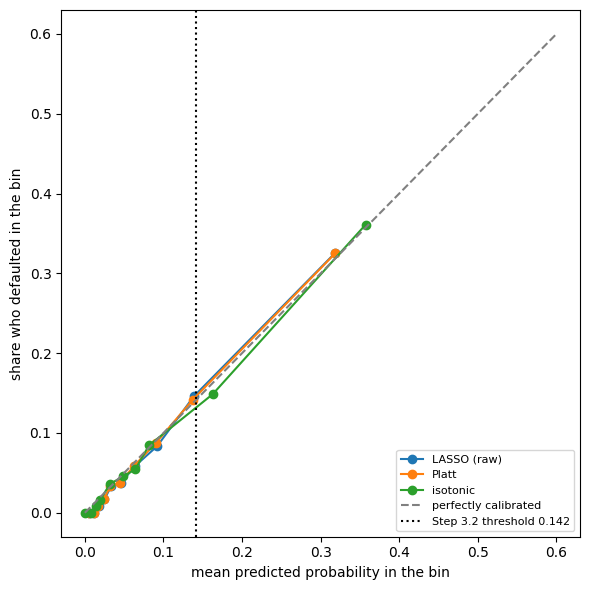

In [22]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in calibrated.items():
    observed, predicted = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, "o-", label=name)
ax.plot([0, 0.6], [0, 0.6], "--", color="gray", label="perfectly calibrated")
ax.axvline(best_t, ls=":", color="black", label=f"Step 3.2 threshold {best_t:.3f}")
ax.set_xlabel("mean predicted probability in the bin")
ax.set_ylabel("share who defaulted in the bin")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The AI's script, pasted unchanged and run after my own calibration cells:

In [23]:
"""
calibration_review.py - calibration review of a credit default (PD) model.

Paste into the notebook after y_test and y_prob exist (it runs automatically),
or call run_calibration_review(y_test, y_prob) yourself.

Model-risk notes
- Platt and isotonic are fitted by K-fold cross-fitting on the test set, so
  every recalibrated probability is scored on rows its calibrator never saw.
  Fitting and scoring a calibrator on the same rows flatters it, isotonic most.
- For production, fit the chosen calibrator on out-of-fold TRAINING
  predictions or a separate calibration sample, never on the test set.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

# --------------------------------------------------------------- settings
COST_FN = 0.60     # loss on an approved applicant who defaults (share of principal)
COST_FP = 0.10     # cost of declining an applicant who would have repaid
T_RULE = COST_FP / (COST_FP + COST_FN)   # cost-optimal cutoff IF probabilities are calibrated
T_PHASE3 = 0.184   # <- set to the threshold you chose in Phase 3

N_BINS = 10        # target number of equal-count bins
MIN_BIN_N = 100    # any bin with fewer rows is merged into a neighbour
LOCAL_N = 300      # rows scored closest to a threshold, used for the local check
N_FOLDS = 5        # cross-fitting folds for the recalibrators
N_BOOT = 1000      # bootstrap draws for Brier-score differences
SEED = 0
EPS = 1e-6
BIG_C = 1e10       # effectively unpenalised logistic regression


# ---------------------------------------------------------------- helpers
def logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))


def wilson_ci(k, n, z=1.96):
    """Wilson interval for a binomial proportion; stays sensible at k = 0 or k = n."""
    phat = k / n
    denom = 1 + z**2 / n
    centre = (phat + z**2 / (2 * n)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def adaptive_edges(p, n_bins=N_BINS, min_n=MIN_BIN_N):
    """Equal-count (quantile) bin edges, then merge bins smaller than min_n.

    Equal-width bins are the wrong default at 7% prevalence: almost every
    applicant scores below 0.3, so the bins above it hold a few rows whose
    observed default rate is 0% or 100% by chance, and the plot shows noise as
    miscalibration. Equal-count bins give every point the same sample size;
    the merge step handles ties and small test sets.
    """
    inner = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1))[1:-1])
    edges = np.concatenate([[0.0], inner, [1.0 + EPS]])
    while len(edges) > 2:
        counts = np.histogram(p, bins=edges)[0]
        small = np.flatnonzero(counts < min_n)
        if small.size == 0:
            break
        b = small[-1]                         # work down from the top
        edges = np.delete(edges, b if b > 0 else 1)   # merge bin b with its neighbour
    return edges


def bin_table(p, y, edges):
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n == 0:
            continue
        k = int(y[m].sum())
        lo, hi = wilson_ci(k, n)
        rows.append({"n": n, "defaults": k, "mean_pred": p[m].mean(),
                     "observed": k / n, "ci_lo": lo, "ci_hi": hi})
    return rows


def brier_decomposition(p, y, edges):
    """Murphy decomposition on the given bins: BS ~= REL - RES + UNC.

    REL (reliability): calibration error, lower is better.
    RES (resolution): how far bin default rates spread from the base rate, higher is better.
    UNC (uncertainty): ybar(1 - ybar), fixed by the data.
    The residual is the within-bin spread of forecasts that binning ignores.
    """
    rows = bin_table(p, y, edges)
    n, ybar = len(y), y.mean()
    rel = sum(r["n"] * (r["mean_pred"] - r["observed"]) ** 2 for r in rows) / n
    res = sum(r["n"] * (r["observed"] - ybar) ** 2 for r in rows) / n
    unc = ybar * (1 - ybar)
    bs = brier_score_loss(y, p)
    return {"brier": bs, "reliability": rel, "resolution": res,
            "uncertainty": unc, "residual": bs - (rel - res + unc)}


def calibration_slope_intercept(p, y):
    """Regress y on logit(p). Perfect calibration: slope 1, intercept 0.
    Slope < 1: predictions too extreme (overfitting). Slope > 1: too timid
    (heavy regularisation). Slope ~1 with intercept != 0: a level shift
    (class weighting, resampling, prevalence drift)."""
    lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    return lr.coef_[0, 0], lr.intercept_[0]


def crossfit_recalibrate(p, y, n_folds=N_FOLDS, seed=SEED):
    """Out-of-fold Platt and isotonic probabilities on the test set.

    Platt is fitted on logit(p), because y_prob is already a probability;
    this is the same sigmoid map CalibratedClassifierCV(method="sigmoid")
    fits on a decision function.
    """
    z = logit(p).reshape(-1, 1)
    platt, iso = np.empty(len(p)), np.empty(len(p))
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for tr, te in skf.split(z, y):
        lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(z[tr], y[tr])
        platt[te] = lr.predict_proba(z[te])[:, 1]
        ir = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
        iso[te] = ir.fit(p[tr], y[tr]).predict(p[te])
    return platt, iso


def bootstrap_brier_gain(y, p_base, p_new, n_boot=N_BOOT, seed=SEED):
    """Paired bootstrap of Brier(base) - Brier(new). Positive means new is better."""
    rng = np.random.default_rng(seed)
    se_base, se_new = (p_base - y) ** 2, (p_new - y) ** 2
    n = len(y)
    gains = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        gains[i] = se_base[idx].mean() - se_new[idx].mean()
    return se_base.mean() - se_new.mean(), np.percentile(gains, [2.5, 97.5])


def expected_cost(y, p, thresholds, exposure=None, c_fn=COST_FN, c_fp=COST_FP):
    """Average cost per applicant when declining every applicant with p > t.
    Pass exposure (e.g. loan amounts) to match a Phase 3 cost that was
    weighted by principal; the rule cutoff T_RULE is unaffected by it."""
    w = np.ones(len(y)) if exposure is None else np.asarray(exposure, dtype=float)
    costs = np.empty(len(thresholds))
    for i, t in enumerate(thresholds):
        decline = p > t
        costs[i] = (c_fn * w[~decline & (y == 1)].sum()
                    + c_fp * w[decline & (y == 0)].sum()) / len(y)
    return costs


def local_check(p, y, t, k=LOCAL_N):
    """Observed default rate among the k applicants scored closest to t.
    The cost rule needs calibration HERE; errors far from t do not move decisions."""
    k = min(k, len(p))
    near = np.argsort(np.abs(p - t))[:k]
    d = int(y[near].sum())
    lo, hi = wilson_ci(d, k)
    return {"t": t, "n": k, "mean_pred": p[near].mean(), "observed": d / k,
            "ci_lo": lo, "ci_hi": hi, "p_min": p[near].min(), "p_max": p[near].max()}


def platt_equivalent_cutoff(p, y, t):
    """Raw-score cutoff that matches declining at calibrated probability t,
    using a Platt map fitted on all rows supplied."""
    lr = LogisticRegression(C=BIG_C, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
    a, b = lr.coef_[0, 0], lr.intercept_[0]
    return 1 / (1 + np.exp(-(logit(t) - b) / a))


# --------------------------------------------------------------- plotting
def plot_reliability(models, y, marks):
    tables = {name: bin_table(q, y, adaptive_edges(q)) for name, q in models.items()}
    top = max(max(r["mean_pred"], r["ci_hi"]) for rows in tables.values() for r in rows)
    top = min(1.0, top * 1.08)
    dodge = 0.004 * top

    fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 8.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
    markers = ["o", "s", "^"]
    for j, (name, rows) in enumerate(tables.items()):
        x = np.array([r["mean_pred"] for r in rows]) + (j - 1) * dodge
        obs = np.array([r["observed"] for r in rows])
        lo = np.array([r["ci_lo"] for r in rows])
        hi = np.array([r["ci_hi"] for r in rows])
        ax.errorbar(x, obs, yerr=[obs - lo, hi - obs], fmt=markers[j % 3] + "-",
                    capsize=3, ms=5, lw=1.2, label=f"{name} ({len(rows)} bins)")
    ax.plot([0, top], [0, top], "k--", lw=0.8, label="perfect calibration")
    for t, lab, ls in marks:
        ax.axvline(t, color="grey", ls=ls, lw=1, label=lab)
        axh.axvline(t, color="grey", ls=ls, lw=1)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_ylabel("Observed default rate in bin (95% Wilson CI)")
    ax.set_title(f"Reliability diagram: equal-count bins, min {MIN_BIN_N} rows per bin")
    ax.legend(fontsize=8, loc="upper left")

    raw = next(iter(models.values()))
    bins = np.linspace(0, top, 50)
    axh.hist(raw, bins=bins, log=True, alpha=0.6, label="raw predictions")
    hidden = int((raw > top).sum())
    axh.set_xlabel("Predicted probability of default")
    axh.set_ylabel("Applicants (log)")
    axh.set_title(f"Score distribution ({hidden} applicants above {top:.2f} not shown)",
                  fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_costs(models, y, grid, marks, exposure=None):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for name, q in models.items():
        c = expected_cost(y, q, grid, exposure)
        ax.plot(grid, c, label=f"{name}: min at {grid[c.argmin()]:.3f}")
    for t, lab, ls in marks:
        ax.axvline(t, color="grey", ls=ls, lw=1, label=lab)
    ax.set_xlabel("Decline threshold")
    ax.set_ylabel("Expected cost per applicant")
    ax.set_title("Cost curve by probability version")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------------- main
def run_calibration_review(y_test, y_prob, exposure=None, t_phase3=T_PHASE3):
    y = np.asarray(y_test).astype(int).ravel()
    p = np.asarray(y_prob, dtype=float)
    if p.ndim == 2:                       # accept predict_proba output
        p = p[:, 1]
    p = p.ravel()
    assert len(p) == len(y) and set(np.unique(y)) <= {0, 1}

    print(f"n = {len(y)}, defaults = {y.sum()}, prevalence = {y.mean():.4f}, "
          f"mean predicted PD = {p.mean():.4f}")

    platt, iso = crossfit_recalibrate(p, y)
    models = {"Raw": p, "Platt (cross-fitted)": platt, "Isotonic (cross-fitted)": iso}

    # 1. Calibration metrics
    print("\n1. Calibration metrics (each version binned on its own quantiles)")
    hdr = (f"{'':26s}{'Brier':>9s}{'REL':>9s}{'RES':>9s}{'UNC':>9s}{'resid':>9s}"
           f"{'slope':>7s}{'icpt':>7s}{'meanPD':>8s}{'AUC':>7s}")
    print(hdr)
    metrics = {}
    for name, q in models.items():
        d = brier_decomposition(q, y, adaptive_edges(q))
        s, i = calibration_slope_intercept(q, y)
        d.update(slope=s, intercept=i, mean_pd=q.mean(), auc=roc_auc_score(y, q))
        metrics[name] = d
        print(f"{name:26s}{d['brier']:9.5f}{d['reliability']:9.5f}{d['resolution']:9.5f}"
              f"{d['uncertainty']:9.5f}{d['residual']:9.5f}{s:7.2f}{i:7.2f}"
              f"{q.mean():8.4f}{d['auc']:7.3f}")
    print("Platt cannot change AUC (monotone map); isotonic can move it slightly through ties.")

    # 2. Does recalibration help?
    print("\n2. Brier improvement over raw (paired bootstrap, 95% CI)")
    gains = {}
    for name in ("Platt (cross-fitted)", "Isotonic (cross-fitted)"):
        g, ci = bootstrap_brier_gain(y, p, models[name])
        gains[name] = (g, ci)
        verdict = ("improves" if ci[0] > 0 else "worsens" if ci[1] < 0
                   else "no detectable change")
        print(f"{name:26s} gain {g:+.5f}  CI [{ci[0]:+.5f}, {ci[1]:+.5f}]  -> {verdict}")

    # 3. Plots
    marks = [(T_RULE, f"rule cutoff {T_RULE:.3f}", ":"),
             (t_phase3, f"Phase 3 threshold {t_phase3:.3f}", "-.")]
    plot_reliability(models, y, marks)
    grid = np.round(np.arange(0.005, 0.95, 0.001), 3)   # wide, so inflated raw scores are not clipped
    plot_costs(models, y, grid, marks, exposure)

    # 4. Threshold check
    print("\n4. Local calibration at the thresholds (raw scores)")
    local = {}
    for t, lab in ((T_RULE, "rule cutoff"), (t_phase3, "Phase 3")):
        lc = local_check(p, y, t)
        local[lab] = lc
        inside = lc["ci_lo"] <= lc["mean_pred"] <= lc["ci_hi"]
        print(f"{lab:12s} t={t:.3f}: {lc['n']} applicants scored "
              f"{lc['p_min']:.3f}-{lc['p_max']:.3f}, mean PD {lc['mean_pred']:.3f}, "
              f"observed {lc['observed']:.3f} [{lc['ci_lo']:.3f}, {lc['ci_hi']:.3f}] "
              f"-> {'consistent' if inside else 'MISCALIBRATED here'}")

    t_equiv = platt_equivalent_cutoff(p, y, T_RULE)
    opt = {name: grid[expected_cost(y, q, grid, exposure).argmin()]
           for name, q in models.items()}
    print(f"\nRaw-score cutoff equivalent to calibrated {T_RULE:.3f} (Platt map): {t_equiv:.3f}")
    print("Empirical cost-minimising threshold: "
          + ", ".join(f"{k} {v:.3f}" for k, v in opt.items()))

    miscal_local = not all(lc["ci_lo"] <= lc["mean_pred"] <= lc["ci_hi"]
                           for lc in local.values())
    recal_helps = any(ci[0] > 0 for _, ci in gains.values())
    print("\nVERDICT")
    if not miscal_local and not recal_helps:
        print("Raw probabilities are consistent with observed default rates around the "
              "threshold and recalibration gives no detectable gain. The cost rule can "
              "be applied to the raw scores.")
    else:
        print("Calibration problem detected near the threshold or fixable by "
              "recalibration. Do not apply the cost rule to raw scores: recalibrate "
              f"(raw-score equivalent of {T_RULE:.3f} is {t_equiv:.3f}), re-derive the "
              "threshold on out-of-fold training data, and confirm on untouched data.")

    return {"metrics": metrics, "gains": gains, "local": local,
            "t_equiv": t_equiv, "optimal_thresholds": opt,
            "p_platt": platt, "p_iso": iso}


if "y_test" in globals() and "y_prob" in globals():
    results = run_calibration_review(y_test, y_prob)
    # Principal-weighted cost, as in Phase 3:
    # results = run_calibration_review(y_test, y_prob, exposure=X_test["loan_amount"].values)

n = 2400, defaults = 170, prevalence = 0.0708, mean predicted PD = 0.0751

1. Calibration metrics (each version binned on its own quantiles)
                              Brier      REL      RES      UNC    resid  slope   icpt  meanPD    AUC
Raw                         0.05445  0.00006  0.00899  0.06582 -0.00243   1.17   0.25  0.0751  0.847
Platt (cross-fitted)        0.05448  0.00006  0.00895  0.06582 -0.00245   1.00  -0.00  0.0709  0.847
Isotonic (cross-fitted)     0.05479  0.00010  0.00887  0.06582 -0.00226   0.65  -0.70  0.0710  0.838
Platt cannot change AUC (monotone map); isotonic can move it slightly through ties.

2. Brier improvement over raw (paired bootstrap, 95% CI)
Platt (cross-fitted)       gain -0.00003  CI [-0.00046, +0.00041]  -> no detectable change
Isotonic (cross-fitted)    gain -0.00034  CI [-0.00139, +0.00064]  -> no detectable change


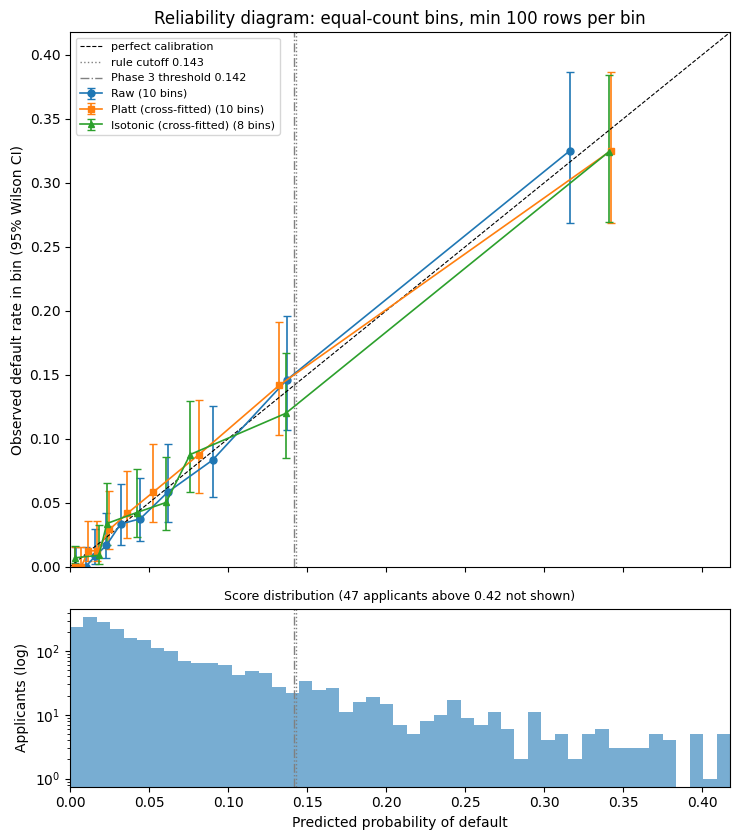

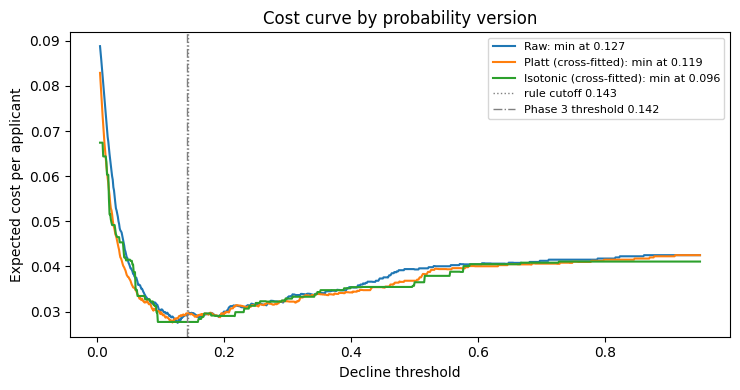


4. Local calibration at the thresholds (raw scores)
rule cutoff  t=0.143: 300 applicants scored 0.101-0.184, mean PD 0.135, observed 0.130 [0.097, 0.173] -> consistent
Phase 3      t=0.142: 300 applicants scored 0.101-0.183, mean PD 0.134, observed 0.133 [0.099, 0.176] -> consistent

Raw-score cutoff equivalent to calibrated 0.143 (Platt map): 0.148
Empirical cost-minimising threshold: Raw 0.127, Platt (cross-fitted) 0.119, Isotonic (cross-fitted) 0.096

VERDICT
Raw probabilities are consistent with observed default rates around the threshold and recalibration gives no detectable gain. The cost rule can be applied to the raw scores.


In [24]:
results = run_calibration_review(y_te, prob_lasso, t_phase3=best_t)

**What it guessed.** Without this notebook's output, the AI reused numbers from an earlier draft: `T_PHASE3 = 0.184`, a cost weighted by `X_test["loan_amount"]`, and a Brier score of 0.052. Here the threshold is 0.142, the cost is per applicant at a fixed \$20,000 principal, and the Brier score is 0.054.

**Changes I made (one line each):**
- Called `run_calibration_review(y_te, prob_lasso, t_phase3=best_t)` instead of using its settings: this notebook's names, threshold 0.142 instead of 0.184, and no `exposure`, since the Phase 3 cost is not weighted by loan amount.
- Ran it after my own calibration cells, because it redefines `expected_cost` and `brier_decomposition` with different arguments.

**Result.** The probabilities are well calibrated near the threshold: among the 300 applicants scored closest to 0.142, mean predicted PD is 0.134 and the observed default rate 0.133 (95% CI 0.099–0.176). The reliability term is 0.00006 (Brier 0.054), and neither Platt nor isotonic gives a detectable Brier gain (both bootstrap intervals span zero). **The Phase 3 threshold survives:** 0.142 on the raw probabilities, 0.148 on Platt-calibrated ones; the AI's Platt-equivalent cutoff is also 0.148.

### Task 4.2: The recommendation

**To:** Head of Risk  **Re:** Vendor default model

**Sign, but we set the decline threshold, not the vendor.**

93% accuracy means nothing on its own: approving everyone scores 92.9%. The model does rank risk (ROC AUC 0.85; PR AUC 0.37 against 0.07 for random). Expected loss per applicant is \$850 if we approve everyone, \$787 at the vendor's 0.5 threshold, and **\$582 at our threshold**.

**Threshold: decline at a predicted default probability of 14% or more.** It catches 95 of 170 defaults. It assumes a missed default costs 60% of principal and a wrongful decline 10% (8% margin plus 2% reputational cost). The probabilities are well calibrated, so the threshold holds.

Use the penalised logistic model: the random forest is not better (McNemar p = 0.14) and is harder to explain to a regulator.

**What would change my answer:** our own loss-given-default data. A lower loss rate raises the threshold.

In [25]:
memo = """To: Head of Risk  Re: Vendor default model

Sign, but we set the decline threshold, not the vendor.

93% accuracy means nothing on its own: approving everyone scores 92.9%. The model does rank risk (ROC AUC 0.85; PR AUC 0.37 against 0.07 for random). Expected loss per applicant is $850 if we approve everyone, $787 at the vendor's 0.5 threshold, and $582 at our threshold.

Threshold: decline at a predicted default probability of 14% or more. It catches 95 of 170 defaults. It assumes a missed default costs 60% of principal and a wrongful decline 10% (8% margin plus 2% reputational cost). The probabilities are well calibrated, so the threshold holds.

Use the penalised logistic model: the random forest is not better (McNemar p = 0.14) and is harder to explain to a regulator.

What would change my answer: our own loss-given-default data. A lower loss rate raises the threshold."""
print(f"{len(memo.split())} words")

150 words
